T1

In [3]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# Entorno base
env = gym.make("FrozenLake-v1", is_slippery=True)
nS = env.observation_space.n   # 16 estados
nA = env.action_space.n        # 4 acciones

# Hiperparámetros comunes
ALPHA      = 0.08   # tasa de aprendizaje
GAMMA      = 0.99   # descuento
EPSILON    = 0.25   # exploración inicial
EPS_DECAY  = 0.996  # decaimiento por episodio
EPS_MIN    = 0.01   # exploración mínima
N_EPISODES = 3000

# Q-table base (para comparación)
Q_base = np.zeros((nS, nA))

def epsilon_greedy(Q, state, eps=EPSILON):
    if np.random.random() < eps:
        return env.action_space.sample()
    max_val = np.max(Q[state])
    best_actions = np.where(Q[state] == max_val)[0]
    return np.random.choice(best_actions)

def run_qlearning(n_eps=N_EPISODES, seed=99):
    np.random.seed(seed)
    Q = np.zeros((nS, nA))
    rewards = []
    for ep in range(n_eps):
        s, _ = env.reset(seed=seed + ep)
        eps = max(EPS_MIN, EPSILON * (EPS_DECAY ** ep))
        ep_r = 0
        for _ in range(200):
            a = epsilon_greedy(Q, s, eps)
            s2, r, done, trunc, _ = env.step(a)
            target = r if done else r + GAMMA * np.max(Q[s2])
            Q[s, a] += ALPHA * (target - Q[s, a])
            s = s2; ep_r += r
            if done or trunc: break
        rewards.append(ep_r)
    return Q, rewards


T2

In [4]:
class TabularModel:
    """Modelo tabular empírico: almacena las transiciones (r, s') observadas por (s, a)."""
    def __init__(self):
        self.table = defaultdict(list)  # {(s, a): [(r, s_next), ...]}
        self.visited = []               # lista de (s, a) visitados

    def update(self, s, a, r, s_next):
        if (s, a) not in self.table:
            self.visited.append((s, a))
        self.table[(s, a)].append((r, s_next))

    def sample(self):
        """Devuelve (s, a) aleatorio de los visitados."""
        idx = np.random.randint(len(self.visited))
        return self.visited[idx]

    def predict(self, s, a):
        """Muestrea (r, s_next) según la distribución empírica observada."""
        transitions = self.table[(s, a)]
        return transitions[np.random.randint(len(transitions))]

    def __len__(self):
        return len(self.visited)

# Prueba rápida
model = TabularModel()
model.update(0, 1, 0.0, 4)
model.update(4, 2, 1.0, 15)
s_sample, a_sample = model.sample()
r_pred, s_next_pred = model.predict(s_sample, a_sample)
print(f"Muestreado: ({s_sample},{a_sample}) → r={r_pred}, s'={s_next_pred}")


Muestreado: (0,1) → r=0.0, s'=4


In [5]:
def run_dyna_q(k=5, n_eps=N_EPISODES, seed=99):
    """Dyna-Q con k pasos de planificación."""
    np.random.seed(seed)
    Q     = np.zeros((nS, nA))
    model = TabularModel()
    rewards = []

    for ep in range(n_eps):
        s, _ = env.reset(seed=seed + ep)
        eps  = max(EPS_MIN, EPSILON * (EPS_DECAY ** ep))
        ep_r = 0

        for _ in range(200):
            # ── PASO 1: Interacción real ──────────────────────
            a = epsilon_greedy(Q, s, eps)
            s2, r, done, trunc, _ = env.step(a)

            # ── PASO 2: Update directo Q-Learning ────────────
            td = r + GAMMA * np.max(Q[s2]) - Q[s, a]
            Q[s, a] += ALPHA * td

            # ── PASO 3: Actualizar modelo ─────────────────────
            model.update(s, a, r, s2)
            s = s2; ep_r += r

            # ── PASO 4: Planificación (k pasos) ──────────────
            if len(model) > 0:
                for _ in range(k):
                    ps, pa    = model.sample()
                    pr, ps2   = model.predict(ps, pa)
                    td_plan   = pr + GAMMA * np.max(Q[ps2]) - Q[ps, pa]
                    Q[ps, pa] += ALPHA * td_plan

            if done or trunc: break
        rewards.append(ep_r)
    return Q, rewards

# Ejecutar para k = 0, 5, 20
results = {k: run_dyna_q(k=k) for k in [0, 5, 20]}


T3

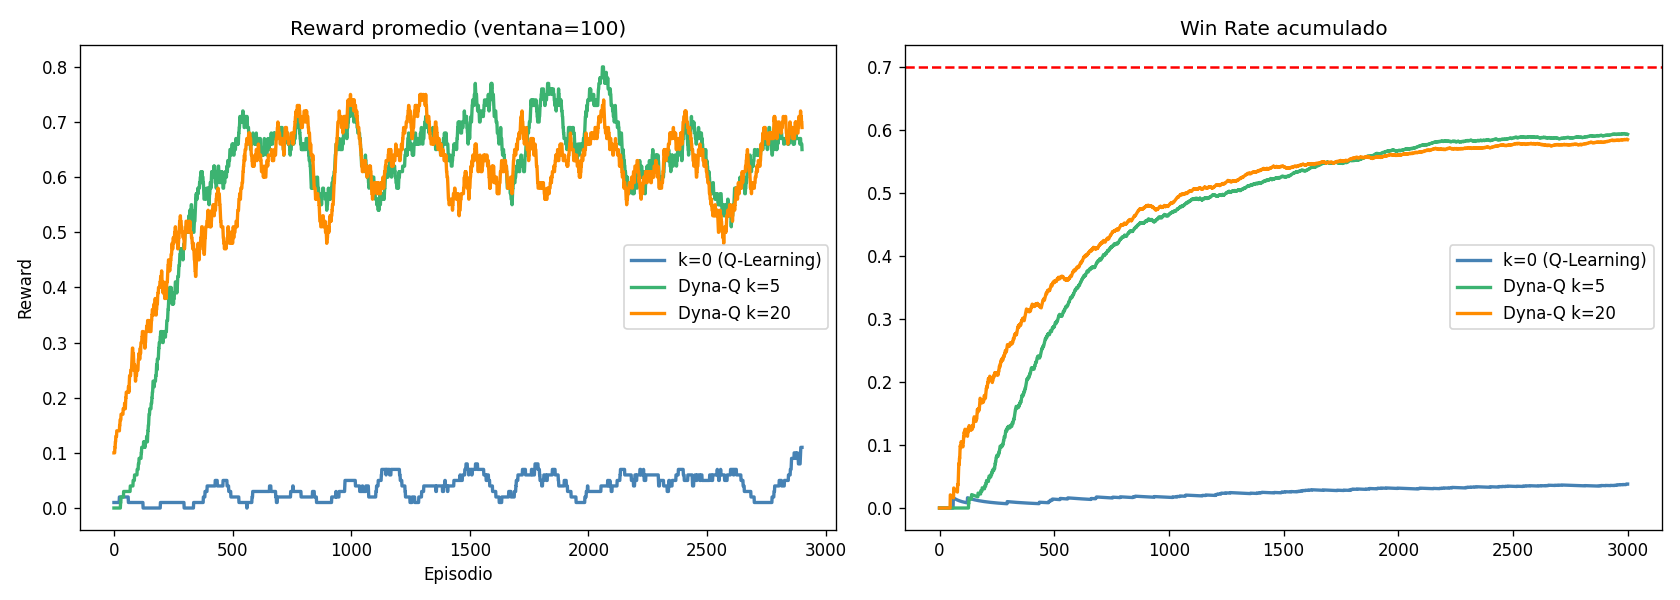

In [6]:
def smooth(x, w=100):
    """Media móvil para suavizar curvas."""
    return np.convolve(x, np.ones(w)/w, mode='valid')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {0: 'steelblue', 5: 'mediumseagreen', 20: 'darkorange'}
labels = {0: 'k=0 (Q-Learning)', 5: 'Dyna-Q k=5', 20: 'Dyna-Q k=20'}

# Plot 1: Reward promedio suavizado
for k, (Q, rews) in results.items():
    axes[0].plot(smooth(rews), color=colors[k], label=labels[k], lw=2)
axes[0].set_title('Reward promedio (ventana=100)'); axes[0].legend()
axes[0].set_xlabel('Episodio'); axes[0].set_ylabel('Reward')

# Plot 2: Win rate acumulado
for k, (Q, rews) in results.items():
    win_rate = np.cumsum(rews) / (np.arange(len(rews))+1)
    axes[1].plot(win_rate, color=colors[k], label=labels[k], lw=2)
axes[1].set_title('Win Rate acumulado'); axes[1].legend()
axes[1].axhline(0.7, color='red', ls='--', label='Meta 70%')

plt.tight_layout(); plt.savefig('dyna_comparison.png', dpi=120)
plt.show()


T4

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim

# Usamos CartPole para el World Model (estado continuo)
env_c = gym.make("CartPole-v1")
state_dim = env_c.observation_space.shape[0]  # 4
n_actions  = env_c.action_space.n              # 2

def collect_dataset(n_episodes=200, policy="random"):
    """Recolecta transiciones (s, a, r, s') del entorno."""
    states, actions, rewards, next_states = [], [], [], []
    for ep in range(n_episodes):
        s, _ = env_c.reset(seed=ep)
        for _ in range(500):
            if policy == "random":
                a = env_c.action_space.sample()
            else:
                a = policy(s)
            s2, r, done, trunc, _ = env_c.step(a)
            states.append(s)
            actions.append(a)
            rewards.append(r)
            next_states.append(s2)
            s = s2
            if done or trunc: break

    return (torch.FloatTensor(np.array(states)),
            torch.LongTensor(np.array(actions)),
            torch.FloatTensor(np.array(rewards)).unsqueeze(1),
            torch.FloatTensor(np.array(next_states)))

S, A, R, S2 = collect_dataset(n_episodes=1000)
print(f"Dataset: {S.shape[0]} transiciones recolectadas")
# Output esperado: Dataset: ~15000-30000 transiciones


Dataset: 22198 transiciones recolectadas


In [9]:
class WorldModel(nn.Module):
    """Predice (s', r) dado (s, a) como one-hot."""
    def __init__(self, state_dim, n_actions):
        super().__init__()
        in_dim = state_dim + n_actions
        self.transition = nn.Sequential(
            nn.Linear(in_dim, 256), nn.ReLU(),
            nn.Linear(256, 256),    nn.ReLU(),
            nn.Linear(256, state_dim)      # → s'
        )
        self.reward_head = nn.Sequential(
            nn.Linear(in_dim, 128), nn.ReLU(),
            nn.Linear(128, 1)              # → r
        )

    def forward(self, s, a_onehot):
        x = torch.cat([s, a_onehot], dim=-1)
        return self.transition(x), self.reward_head(x)

# One-hot encoding de acciones
def to_onehot(a, n=2):
    oh = torch.zeros(len(a), n)
    oh.scatter_(1, a.unsqueeze(1), 1.0)
    return oh

# División Train (80%) / Test (20%)
split = int(0.8 * len(S))
S_train, A_train = S[:split], A[:split]
R_train, S2_train = R[:split], S2[:split]
A_oh_train = to_onehot(A_train)

# Entrenamiento
torch.manual_seed(42)
world_model = WorldModel(state_dim, n_actions)
optimizer   = optim.Adam(world_model.parameters(), lr=1e-3)
loss_fn     = nn.MSELoss()

for epoch in range(50):
    s_pred, r_pred = world_model(S_train, A_oh_train)
    loss = loss_fn(s_pred, S2_train) + 0.5 * loss_fn(r_pred, R_train)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d}  Loss={loss.item():.4f}")


Epoch   0  Loss=0.7201
Epoch  10  Loss=0.2513
Epoch  20  Loss=0.1053
Epoch  30  Loss=0.0395
Epoch  40  Loss=0.0200


In [10]:
# Evaluar el modelo en datos de test (hold-out 20%)
S_test, A_test = S[split:], A[split:]
R_test, S2_test = R[split:], S2[split:]
A_oh_test = to_onehot(A_test)

world_model.eval()
with torch.no_grad():
    s_pred_test, r_pred_test = world_model(S_test, A_oh_test)
    loss_s = loss_fn(s_pred_test, S2_test).item()
    loss_r = loss_fn(r_pred_test, R_test).item()

print(f"Loss transición (test): {loss_s:.4f}")
print(f"Loss recompensa (test): {loss_r:.4f}")

# Comparar 5 predicciones vs realidad
for i in range(5):
    print(f"Real s': {S2_test[i].numpy().round(3)}")
    print(f"Pred s': {s_pred_test[i].numpy().round(3)}")
    print("---")


Loss transición (test): 0.0006
Loss recompensa (test): 0.0269
Real s': [-0.049 -0.404  0.137  0.82 ]
Pred s': [-0.057 -0.387  0.138  0.811]
---
Real s': [-0.057 -0.6    0.153  1.153]
Pred s': [-0.051 -0.597  0.126  1.161]
---
Real s': [-0.069 -0.407  0.176  0.912]
Pred s': [-0.062 -0.391  0.168  0.904]
---
Real s': [-0.077 -0.604  0.195  1.254]
Pred s': [-0.059 -0.598  0.162  1.265]
---
Real s': [-0.089 -0.412  0.22   1.029]
Pred s': [-0.06  -0.391  0.202  1.024]
---


In [12]:
def model_rollout(wm, start_state, policy_fn, H=5):
    """Genera H pasos sintéticos desde start_state."""
    traj = []
    s = torch.FloatTensor(start_state).unsqueeze(0)
    for _ in range(H):
        a = policy_fn(s.numpy()[0])
        a_oh = to_onehot(torch.LongTensor([a]))
        with torch.no_grad():
            s_next, r = wm(s, a_oh)
        traj.append((s.numpy()[0], a, r.item(), s_next.numpy()[0]))
        s = s_next
    return traj

# Generar rollout desde estado inicial
s0, _ = env_c.reset(seed=0)
rand_policy = lambda s: env_c.action_space.sample()
traj = model_rollout(world_model, s0, rand_policy, H=10)

for i, (s, a, r, s2) in enumerate(traj):
    print(f"  t={i}: a={a}, r={r:.2f}, |s'|={np.linalg.norm(s2):.3f}")


  t=0: a=1, r=0.84, |s'|=0.400
  t=1: a=1, r=0.89, |s'|=0.779
  t=2: a=1, r=0.98, |s'|=1.128
  t=3: a=0, r=1.18, |s'|=0.775
  t=4: a=1, r=0.97, |s'|=1.148
  t=5: a=0, r=1.18, |s'|=0.811
  t=6: a=0, r=1.08, |s'|=0.512
  t=7: a=1, r=0.90, |s'|=0.898
  t=8: a=0, r=1.10, |s'|=0.593
  t=9: a=0, r=1.00, |s'|=0.353


T5: